In [13]:
import numpy as np
import matplotlib.pyplot as plt

from data.paths import path_1, path_2

In [29]:
x = np.array(path_1[:, 0])
y = np.array(path_1[:, 1])

x_sparse = x[::5]
y_sparse = y[::5]

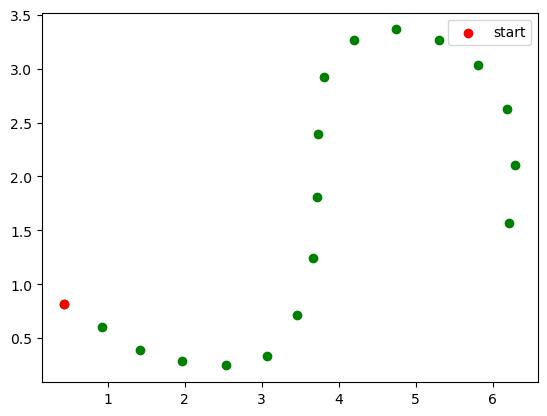

In [32]:
# plt.plot(x, y, c='b')
plt.scatter(x_sparse, y_sparse, c='g')
plt.scatter(x[0], y[0], c='r', label='start')
plt.legend()
plt.show()

In [10]:
x_2 = np.array(path_2[:, 0])
y_2 = np.array(path_2[:, 1])

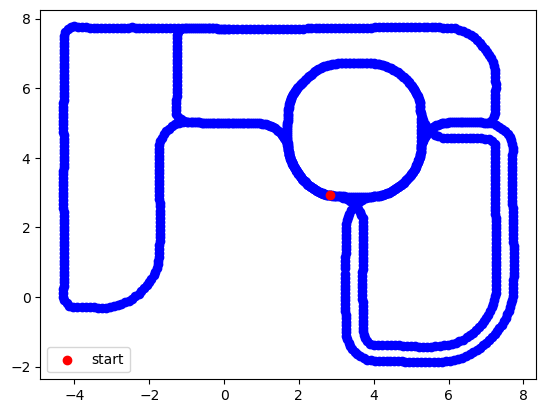

In [11]:
plt.scatter(x_2, y_2, c='b')
plt.scatter(x_2[0], y_2[0], c='r', label='start')
plt.legend(loc=3)
plt.show()

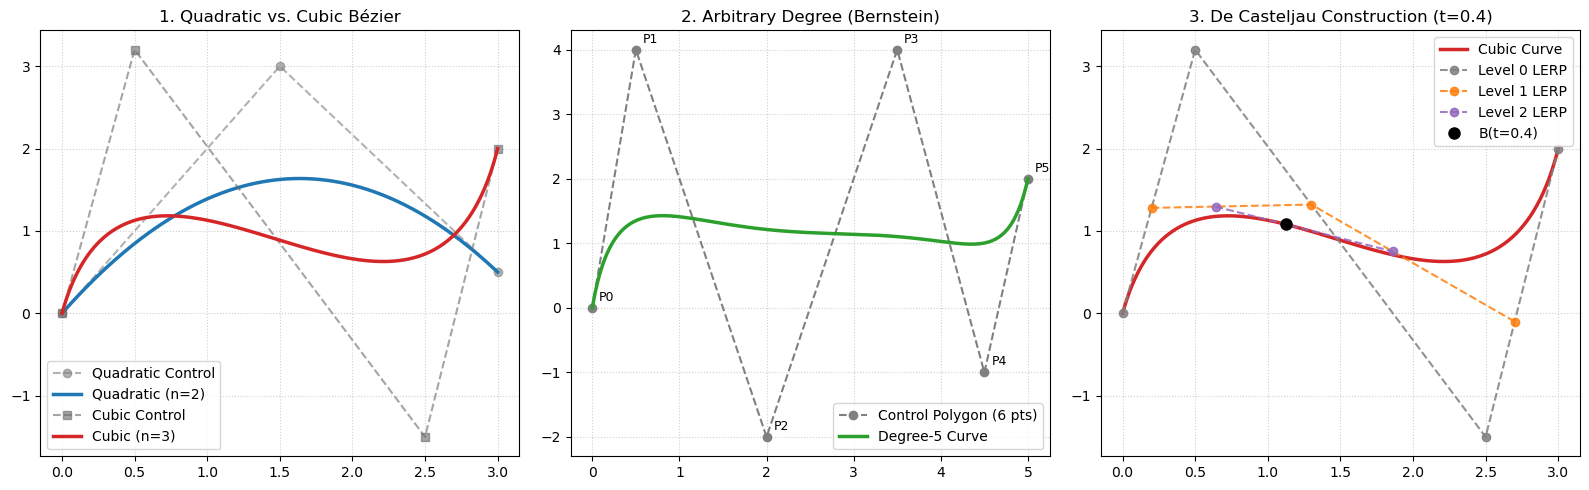

In [12]:
from scipy.special import comb

# ---------------------------------------------------------
# 1. Direct Vectorized Cubic Bézier (4 Control Points)
# ---------------------------------------------------------
def cubic_bezier(P0, P1, P2, P3, num_points=200):
    t = np.linspace(0.0, 1.0, num_points)[:, np.newaxis]  # Shape (N, 1)
    curve = (
        ((1 - t) ** 3) * P0
        + 3 * ((1 - t) ** 2) * t * P1
        + 3 * (1 - t) * (t ** 2) * P2
        + (t ** 3) * P3
    )
    return curve


# ---------------------------------------------------------
# 2. General Degree-N Bézier (Bernstein Polynomial Matrix)
# ---------------------------------------------------------
def general_bezier(control_points, num_points=200):
    pts = np.asarray(control_points, dtype=float)
    n = len(pts) - 1
    t = np.linspace(0.0, 1.0, num_points)[:, np.newaxis]  # Shape (N, 1)
    i = np.arange(n + 1)                                  # Shape (n+1,)

    # Compute Bernstein basis matrix of shape (N, n+1)
    bernstein_basis = comb(n, i) * ((1 - t) ** (n - i)) * (t ** i)
    return bernstein_basis @ pts                          # Shape (N, 2)


# ---------------------------------------------------------
# 3. De Casteljau's Algorithm (Returns all construction levels)
# ---------------------------------------------------------
def de_casteljau_levels(control_points, t_val):
    levels = [np.asarray(control_points, dtype=float)]
    while len(levels[-1]) > 1:
        prev = levels[-1]
        next_level = (1.0 - t_val) * prev[:-1] + t_val * prev[1:]
        levels.append(next_level)
    return levels


# ---------------------------------------------------------
# Plotting All Three Examples
# ---------------------------------------------------------
if __name__ == "__main__":
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # --- Plot 1: Quadratic vs Cubic S-Curve ---
    quad_pts = np.array([[0.0, 0.0], [1.5, 3.0], [3.0, 0.5]])
    cubic_pts = np.array([[0.0, 0.0], [0.5, 3.2], [2.5, -1.5], [3.0, 2.0]])

    quad_curve = general_bezier(quad_pts)
    cubic_curve = cubic_bezier(*cubic_pts)

    ax = axes[0]
    ax.plot(quad_pts[:, 0], quad_pts[:, 1], "o--", color="gray", alpha=0.6, label="Quadratic Control")
    ax.plot(quad_curve[:, 0], quad_curve[:, 1], "-", lw=2.5, color="#1f77b4", label="Quadratic (n=2)")
    ax.plot(cubic_pts[:, 0], cubic_pts[:, 1], "s--", color="dimgray", alpha=0.6, label="Cubic Control")
    ax.plot(cubic_curve[:, 0], cubic_curve[:, 1], "-", lw=2.5, color="#d62728", label="Cubic (n=3)")
    ax.set_title("1. Quadratic vs. Cubic Bézier")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

    # --- Plot 2: High-Order (5th Degree / 6 Control Points) ---
    high_order_pts = np.array([
        [0.0, 0.0], [0.5, 4.0], [2.0, -2.0],
        [3.5, 4.0], [4.5, -1.0], [5.0, 2.0]
    ])
    high_curve = general_bezier(high_order_pts)

    ax = axes[1]
    ax.plot(high_order_pts[:, 0], high_order_pts[:, 1], "o--", color="gray", label="Control Polygon (6 pts)")
    ax.plot(high_curve[:, 0], high_curve[:, 1], "-", lw=2.5, color="#2ca02c", label="Degree-5 Curve")
    for idx, (x, y) in enumerate(high_order_pts):
        ax.annotate(f"P{idx}", (x, y), textcoords="offset points", xytext=(5, 5), fontsize=9)
    ax.set_title("2. Arbitrary Degree (Bernstein)")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

    # --- Plot 3: De Casteljau Geometric Subdivision at t = 0.4 ---
    t_sample = 0.4
    levels = de_casteljau_levels(cubic_pts, t_sample)

    ax = axes[2]
    ax.plot(cubic_curve[:, 0], cubic_curve[:, 1], "-", lw=2.5, color="#d62728", label="Cubic Curve")
    colors = ["#7f7f7f", "#ff7f0e", "#9467bd"]
    for lvl_idx, lvl_pts in enumerate(levels[:-1]):
        ax.plot(
            lvl_pts[:, 0], lvl_pts[:, 1], "o--",
            color=colors[lvl_idx], alpha=0.85, label=f"Level {lvl_idx} LERP"
        )
    final_pt = levels[-1][0]
    ax.plot(final_pt[0], final_pt[1], "ko", markersize=8, label=f"B(t={t_sample})")
    ax.set_title(f"3. De Casteljau Construction (t={t_sample})")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()